# D14. 성능 비교 & 상용 API: 같은 시험지로 채점하고, 고르고, 공개하기

**음성 AI 전문가 과정 (160h) | 3주차 M3 한국어 ASR Fine-tuning | 4시간**

## 학습 목표
1. 여러 음성 인식 시스템을 **공정하게 비교하는 규칙**(같은 시험지 · 같은 채점 · 누수 없음)을 세운다.
2. 원래 Whisper · **D12 Full** · **D13 LoRA** 모델을 같은 시험 세트로 채점하고 **RTF**를 잰다.
3. **OpenAI · Google · NAVER CLOVA** 음성 인식 API를 **REST로 직접 호출**하고, **지연 시간 · 과금 단위 · 비용**을 계산한다.
4. **리더보드**(CER · 용어 정확도 · 속도 · 비용 · 개인정보)를 만들고 요구 사항에 맞는 시스템을 고른다.
5. **부트스트랩**으로 'CER 차이가 우연인지'를 신뢰구간으로 판단한다.
6. 오류를 종류별로 나눠 **어디서 왜 틀리는지** 분석한다.
7. 모델 · 어댑터를 **Hugging Face Hub**에 모델 카드와 함께 올리고 다시 불러온다.

## 오늘의 실습 흐름
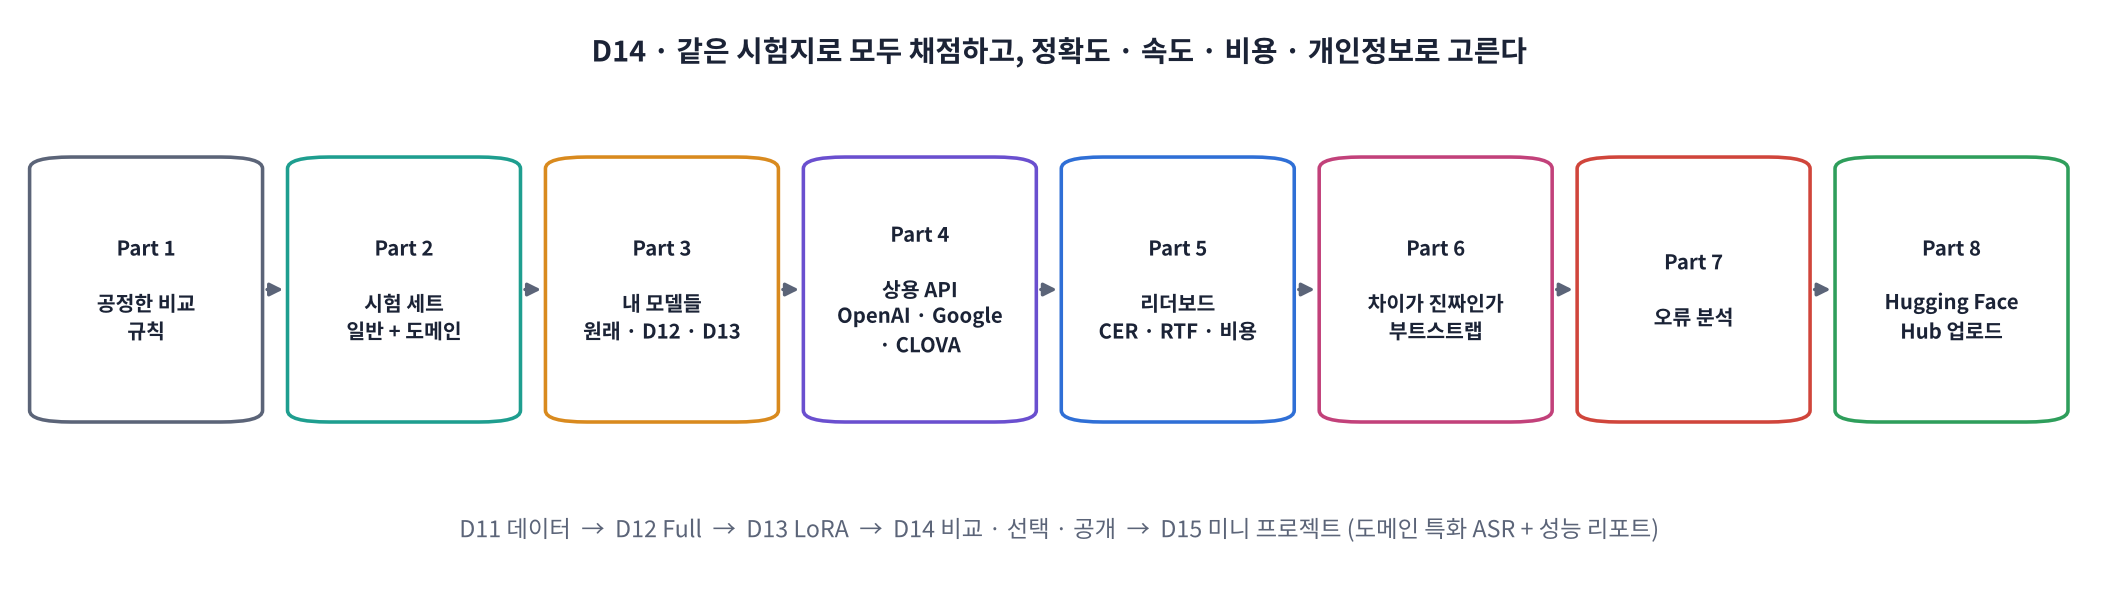

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | 공정한 비교 규칙, 시험 세트, 내 모델들 채점 · RTF | Part 0 ~ 3, 워크시트 1교시 |
| 2교시 | 상용 API 3종 REST 호출, 지연 · 과금 단위 · 비용 | Part 4, 워크시트 2교시 |
| 3교시 | 리더보드, 부트스트랩 신뢰구간, 오류 분석 | Part 5 ~ 7, 워크시트 3교시 |
| 4교시 | Hugging Face Hub 업로드 · 모델 카드 · 다시 불러오기, 정리 | Part 8 ~ 9, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day14/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day14/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🔍 **코드 해설** | 주요 코드를 한 줄씩 |

> ⚙️ **T4 GPU** 런타임을 권장합니다. **D12 모델 · D13 어댑터**를 Google Drive에 저장해 두었다면 그대로 불러옵니다. 없으면 그 시스템은 건너뜁니다.
>
> 🔑 **API 키는 모두 선택**입니다. Colab 왼쪽 🔑 **보안 비밀**에 넣은 키만 사용하고, 없는 API는 건너뜁니다. 키를 노트북 코드에 직접 쓰지 마세요. (`OPENAI_API_KEY` · `GOOGLE_API_KEY` · `CLOVA_CLIENT_ID` · `CLOVA_CLIENT_SECRET` · `HF_TOKEN`)
>
> 💸 API 호출은 **실제 요금이 나갑니다**. 오늘 시험 세트(약 160문장, 15분 안팎)를 API 하나로 한 번 돌리면 대략 수십 원 ~ 수백 원 수준입니다(Part 4 계산 참고).

> 🎬 **애니메이션 D14-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#flow) — Part 1~8 로드맵

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D8 ~ D13과 같은 방식)**: Colab 기본 패키지 버전을 고정한 채 필요한 것만 설치합니다. 상용 API는 회사별 SDK 대신 **`requests`로 REST를 직접 호출**합니다. SDK마다 의존성(grpc · protobuf 등)이 달라 버전 충돌이 잦기 때문이고, 무엇을 보내고 받는지 눈으로 보기에도 좋습니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "transformers", "tokenizers", "huggingface-hub",
        "datasets", "accelerate", "click", "numpy", "protobuf", "requests"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

!pip install -q -c colab_constraints.txt peft datasets jiwer soundfile librosa requests
!pip install -q --no-deps gTTS
print("✅ 설치 완료")

In [ ]:
import os, io, re, time, math, json, base64, random, hashlib, shutil
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import requests
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from gtts import gTTS

SR = 16000
random.seed(0); np.random.seed(0); torch.manual_seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
import importlib.metadata as md
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "peft", "huggingface-hub", "requests"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (맛보기 모드)")

def secret(name):                                       # Colab 보안 비밀 → 없으면 환경 변수 → 없으면 None
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name)

KEYS = {k: secret(k) for k in ["OPENAI_API_KEY", "GOOGLE_API_KEY", "CLOVA_CLIENT_ID", "CLOVA_CLIENT_SECRET", "HF_TOKEN"]}
for k, v in KEYS.items():
    print(f"  {k:20s} {'✓ 있음' if v else '— 없음 (해당 단계 건너뜀)'}")

### 0-1. 실험 설정과 Google Drive 연결
D12 · D13에서 Drive에 저장한 폴더를 찾습니다. 경로가 다르면 `d12_dirs` · `d13_dirs`를 고치세요. **D13과 같은 도메인**을 고르세요.

In [ ]:
MOUNT_DRIVE = True
if MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive 연결 건너뜀:", type(e).__name__)

CFG = dict(
    domain     = "의료",                                     # D13에서 고른 도메인: "의료" | "법률" | "산업"
    model_name = "openai/whisper-small" if GPU else "openai/whisper-tiny",
    n_general  = 100 if GPU else 12,                         # Zeroth 공식 시험 세트에서 고를 문장 수
    gpu_cost_per_hour = 0.5,                                 # 가정: 내 GPU 1시간 비용 (USD) — 클라우드 요금표 보고 고치기
    krw_per_usd = 1400,                                      # 가정: 환율
)
EN = {"의료": "medical", "법률": "legal", "산업": "industry"}[CFG["domain"]]
CFG["d12_dirs"] = ["/content/drive/MyDrive/whisper-small-ko-d12", "whisper-small-ko/final"]
CFG["d13_dirs"] = [f"/content/drive/MyDrive/lora-{EN}", f"lora-{EN}"]
CFG["public_ft"] = "jiwon65/whisper-small_korean-zeroth"     # (참고) Hub에 공개된 한국어 Fine-tuned 모델 예 — 없거나 실패하면 건너뜀
first = lambda paths: next((p for p in paths if os.path.isdir(p)), None)
D12_DIR, D13_DIR = first(CFG["d12_dirs"]), first(CFG["d13_dirs"])
print("D12 모델 :", D12_DIR or "없음 → 건너뜀")
print("D13 어댑터:", D13_DIR or "없음 → 건너뜀")

## Part 1. 공정한 비교의 규칙

> 💬 **쉽게 말하면**: 모델 비교는 **시험 감독**과 같습니다. 모두 **같은 시험지**를 풀고, **같은 채점 기준**으로 매기고, 누구도 **시험지를 미리 보지 않아야** 합니다. 그리고 점수만이 아니라 **풀이 시간(속도) · 수강료(비용) · 답안지 보관(개인정보)** 까지 봐야 실제로 고를 수 있습니다.

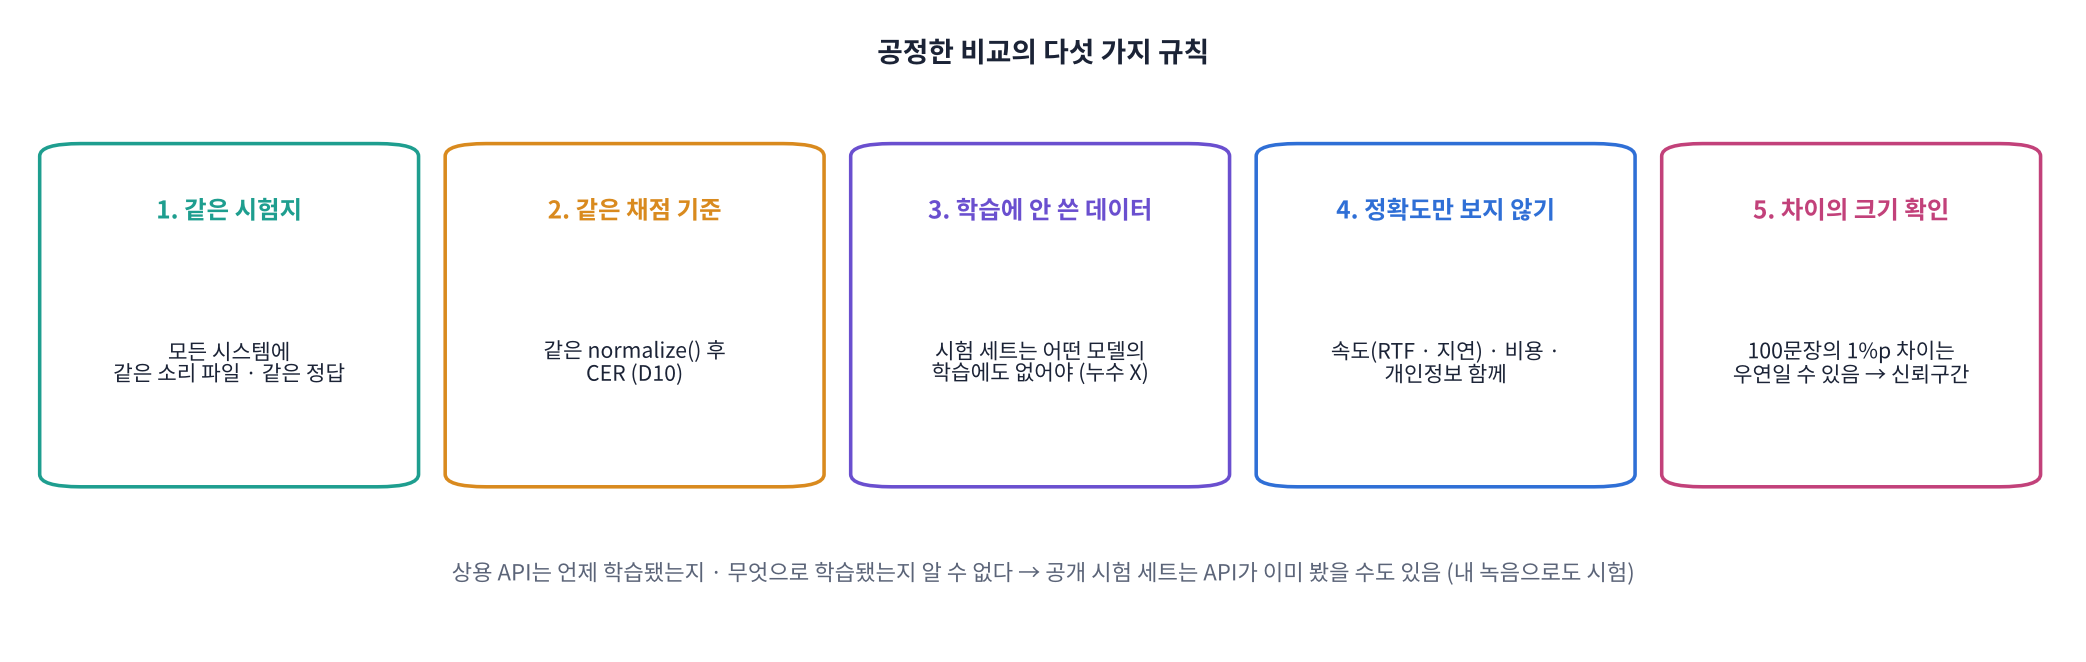

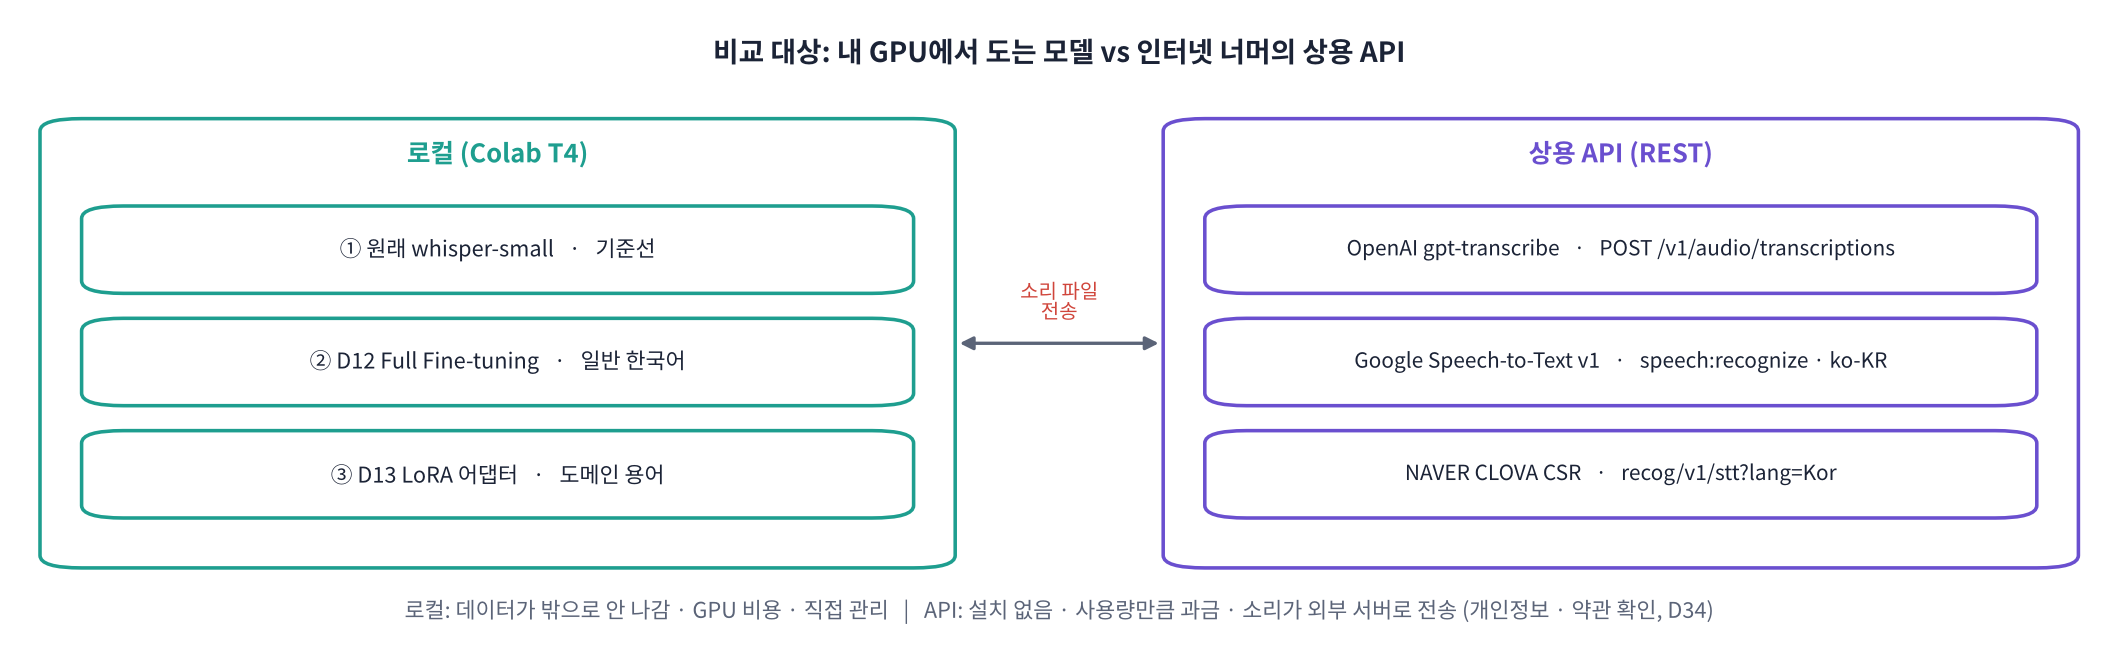

> 🍎 **비유: 맛집 비교.** 같은 메뉴(시험 세트)를 시켜서 같은 기준(normalize)으로 맛을 매기되, **가격 · 대기 시간 · 배달 가능 여부(데이터를 밖으로 보내도 되는지)** 까지 따져야 '우리 회사 점심'을 고를 수 있습니다. 한 번 먹어 본 것(100문장)만으로 1점 차이를 단정하면 안 됩니다(Part 6).

> 🎬 **애니메이션 D14-2:** [불공정한 비교 찾기](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#fair) — 규칙 하나를 어기면 순위가 어떻게 바뀌는지

## Part 2. 시험 세트: 일반 + 도메인

| 시험 세트 | 출처 | 개수 | 재는 것 |
|---|---|---|---|
| **일반** | Zeroth 공식 test (무작위) | 100 | 일반 낭독 한국어 실력 (D12가 강해야 함) |
| **도메인** | D13과 같은 용어 20개 × 시험용 문장 틀 3개, gTTS | 60 | 전문 용어 (D13이 강해야 함) |

> ⚠️ D13 시험 문장과 **같은 틀 · 같은 용어**로 만들어 D13 결과와 이어집니다. D13 어댑터는 이 틀을 학습에 쓰지 않았습니다(누수 없음). 반면 **상용 API는 무엇으로 학습했는지 알 수 없어**, Zeroth 같은 공개 데이터는 이미 봤을 가능성도 있습니다. 그래서 실제 선택 전에는 **내가 녹음한 데이터**로 꼭 다시 시험합니다(과제).

In [ ]:
from datasets import load_dataset, Audio as HFAudio

def read_audio(ex):
    y, sr = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y.astype(np.float32)

zt = load_dataset("kresnik/zeroth_korean", split="test").cast_column("audio", HFAudio(decode=False))
general = []
for ex in zt.shuffle(seed=0):
    y = read_audio(ex)
    if ex["text"].strip() and len(y) / SR <= 30:
        general.append(dict(audio=y, text=ex["text"].strip(), term=None, set="일반"))
    if len(general) >= CFG["n_general"]:
        break

TERMS = {
    "의료": ["심방세동", "트로포닌", "와파린", "메트포르민", "아세트아미노펜", "크레아티닌", "당화혈색소", "심근경색",
             "폐색전증", "패혈증", "기관지확장제", "프레드니솔론", "혈소판감소증", "갑상선기능저하증", "신우신염", "대상포진",
             "담낭절제술", "관상동맥조영술", "항응고제", "인슐린 글라진"],
    "법률": ["소멸시효", "가압류", "근저당권", "손해배상청구", "집행유예", "기판력", "채권자대위권", "부당이득반환",
             "공탁금", "항소이유서", "가처분", "유치권", "사해행위취소", "성년후견인", "상계", "확정판결",
             "소송비용", "공시송달", "이행권고결정", "지급명령"],
    "산업": ["공압 실린더", "서보모터", "인버터 과전류", "PLC 래더", "컨베이어 벨트", "용접 비드", "사출 성형", "금형 온도",
             "진동 센서", "베어링 마모", "유압 펌프", "냉각탑", "안전 인터록", "비상 정지", "토크 렌치", "치공구",
             "공정 능력 지수", "불량률", "설비 종합 효율", "예지 정비"],
}[CFG["domain"]]
TEST_TEMPLATES = ["기록지에 {t} 항목을 표시해 주세요", "{t} 경과를 내일 다시 보겠습니다", "고객에게 {t} 설명을 드렸습니다"]   # D13 시험용 틀

os.makedirs("tts_cache", exist_ok=True)
def tts(text):
    path = f"tts_cache/{hashlib.md5(text.encode()).hexdigest()}.mp3"
    for k in range(3):
        try:
            if not os.path.exists(path):
                gTTS(text, lang="ko").save(path)
            break
        except Exception as e:
            print("gTTS 재시도:", e); time.sleep(3 * (k + 1))
    y, _ = librosa.load(path, sr=SR, mono=True)
    return librosa.effects.trim(y, top_db=35)[0].astype(np.float32)

domain = [dict(audio=tts(t.format(t=term)), text=t.format(t=term), term=term, set="도메인") for t in TEST_TEMPLATES for term in TERMS]
ROWS = general + domain
for r in ROWS:                                          # API로 보낼 16 kHz · 16-bit WAV 바이트
    buf = io.BytesIO(); sf.write(buf, r["audio"], SR, format="WAV", subtype="PCM_16"); r["wav"] = buf.getvalue()
    r["dur"] = len(r["audio"]) / SR
AUDIO_SEC = sum(r["dur"] for r in ROWS)
print(f"일반 {len(general)}개 · 도메인 {len(domain)}개 · 전체 소리 {AUDIO_SEC / 60:.1f}분")

## Part 3. 내 모델들 채점하기: 원래 · D12 Full · D13 LoRA

> 💬 **쉽게 말하면**: 세 모델(+ 참고용 공개 모델)을 **같은 함수**로 받아쓰게 하고, 정답 · 예측을 모두 저장합니다. 채점은 Part 5에서 한꺼번에 합니다. 속도는 **RTF = 처리 시간 ÷ 소리 길이**(D8)로 잽니다.

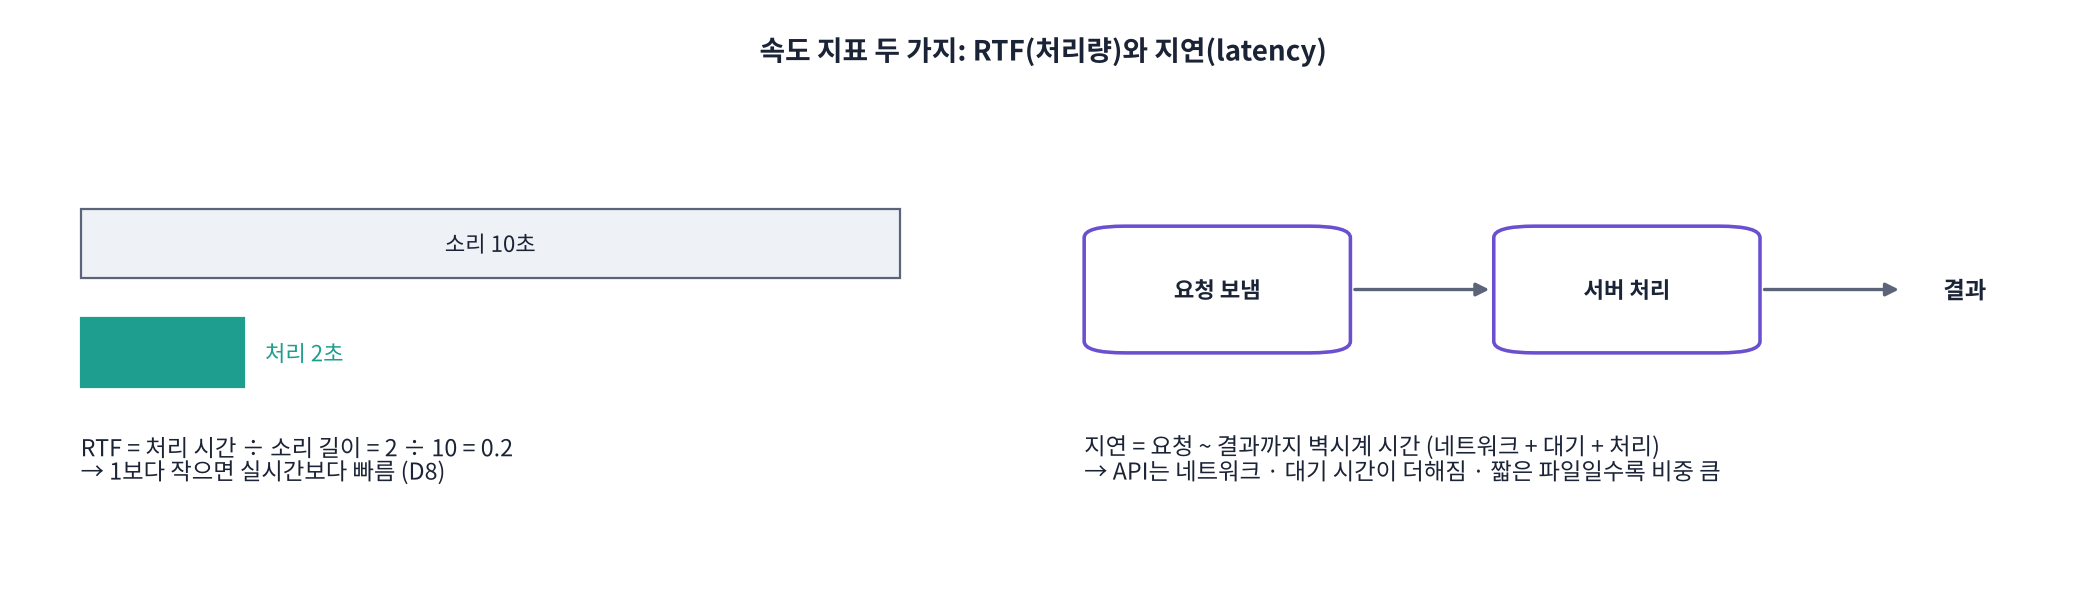

> 📐 **핵심 식 하나: RTF = 처리 시간 ÷ 소리 길이** — 0.1이면 10분 소리를 1분에 처리. 1보다 크면 실시간보다 느림.

> 🎬 **애니메이션 D14-3:** [RTF와 지연](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#latency) — 묶음 크기 · 네트워크를 바꾸며 RTF와 지연 비교

In [ ]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
from peft import PeftModel

processor = WhisperProcessor.from_pretrained(CFG["model_name"], language="korean", task="transcribe")

def prep(m):
    m.generation_config.language = "korean"; m.generation_config.task = "transcribe"
    return m.to(DEVICE).eval()

LOCAL = {}
LOCAL["① 원래 Whisper"] = prep(WhisperForConditionalGeneration.from_pretrained(CFG["model_name"]))
if D12_DIR:
    LOCAL["② D12 Full"] = prep(WhisperForConditionalGeneration.from_pretrained(D12_DIR))
if D13_DIR:
    base = WhisperForConditionalGeneration.from_pretrained(CFG["model_name"])
    LOCAL["③ D13 LoRA"] = prep(PeftModel.from_pretrained(base, D13_DIR).merge_and_unload())   # 병합해 속도 손해 없이
try:
    LOCAL["(참고) 공개 Fine-tuned"] = prep(WhisperForConditionalGeneration.from_pretrained(CFG["public_ft"]))
except Exception as e:
    print("공개 모델 건너뜀:", type(e).__name__)
print("로컬 시스템:", list(LOCAL))

### 🧩 빈칸 실습 1: RTF 재기
처리 시간을 **전체 소리 길이(초)** 로 나눕니다. Part 2에서 만든 변수 이름을 넣으세요. GPU는 비동기로 돌기 때문에 시간을 재기 전에 `torch.cuda.synchronize()`로 계산이 끝나기를 기다립니다.

In [ ]:
# 🧩 빈칸 실습 1
def transcribe_local(m, rows, bs=16):
    out = []
    for i in range(0, len(rows), bs):
        feats = processor.feature_extractor([r["audio"] for r in rows[i:i + bs]], sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
        with torch.no_grad():
            ids = m.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=128)
        out += [t.strip() for t in processor.batch_decode(ids, skip_special_tokens=True)]
    return out

RESULTS = {}
for name, m in LOCAL.items():
    if GPU: torch.cuda.synchronize()
    t0 = time.time()
    preds = transcribe_local(m, ROWS)
    if GPU: torch.cuda.synchronize()
    elapsed = time.time() - t0
    rtf = elapsed / ____                                                                  # 빈칸 1
    RESULTS[name] = dict(preds=preds, kind="로컬", rtf=rtf, latency=elapsed / len(ROWS),
                         usd_per_hour=rtf * CFG["gpu_cost_per_hour"], external=False)
    print(f"{name:22s} {elapsed:6.1f}초 · RTF {rtf:.3f} · 소리 1시간당 약 ${rtf * CFG['gpu_cost_per_hour']:.3f} (GPU 시간 비용 가정)")
check(all(abs(v["rtf"] * AUDIO_SEC - v["latency"] * len(ROWS)) < 1e-6 for v in RESULTS.values()), hint="빈칸 1 = AUDIO_SEC")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
rtf = elapsed / AUDIO_SEC
```

**해설**: RTF는 '소리 1초를 처리하는 데 걸린 초'입니다. T4에서 whisper-small을 16개씩 묶어 돌리면 보통 0.1 이하(실시간의 10배 이상 빠름)입니다. 로컬 비용은 **GPU를 빌린 시간**으로 계산합니다: 소리 1시간 처리 비용 ≈ RTF × GPU 시간당 요금. 단, GPU를 하루 종일 켜 두면 놀고 있는 시간도 비용이므로 **사용량이 적으면 API가 더 싸고, 많으면 로컬이 싸집니다**(손익분기, D14-5).

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day14/worksheet.html)** — 공정한 비교 다섯 규칙, 같은 normalize, 누수, 공개 시험 세트의 한계, 일반 · 도메인 시험 세트, RTF 계산, GPU 비동기와 synchronize, 로컬 비용
>
> 10문항을 풀고 **채점하기**를 누르세요. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 4. 상용 API를 REST로 직접 부르기

> 💬 **쉽게 말하면**: 상용 API는 **HTTP 요청 한 번**입니다. ① 주소(URL) ② 신분증(API 키, 헤더) ③ 소리(파일 또는 base64) ④ 옵션(언어)을 보내면 ⑤ JSON으로 글자가 돌아옵니다. 회사마다 이 다섯 가지의 **모양만 다릅니다**.

| | OpenAI | Google Cloud | NAVER CLOVA CSR |
|---|---|---|---|
| 주소 | `POST https://api.openai.com/v1/audio/transcriptions` | `POST https://speech.googleapis.com/v1/speech:recognize?key=…` | `POST https://naveropenapi.apigw.ntruss.com/recog/v1/stt?lang=Kor` |
| 인증 | `Authorization: Bearer 키` | URL의 `key=` (API 키) | `X-NCP-APIGW-API-KEY-ID` · `X-NCP-APIGW-API-KEY` 헤더 |
| 소리 | multipart 파일 (25 MB까지) | JSON 안에 base64 (동기 1분까지) | 본문에 그대로 (60초까지) |
| 언어 | `languages[]=ko` (gpt-transcribe) | `languageCode: "ko-KR"` | `lang=Kor` |
| 결과 | `{"text": …}` | `results[].alternatives[0].transcript` | `{"text": …}` |

> 📌 **2026년 10월 기준 정보**입니다. OpenAI는 `gpt-transcribe`를 권장 모델로 안내하고 `whisper-1` · `gpt-4o-transcribe` · `gpt-4o-mini-transcribe`는 **2027년 2월 26일 종료 예정**이라고 밝히고 있습니다. API 이름 · 가격 · 한도는 자주 바뀌므로 **쓰기 전에 공식 문서를 확인**하세요.
>
> 🔒 API로 보내는 소리는 **회사 서버로 전송**됩니다. 오늘은 공개 데이터(Zeroth)와 합성 음성만 보냅니다. 실제 고객 · 환자 녹음은 **동의 · 약관 · 데이터 보관 정책**을 확인한 뒤에만 보냅니다(D34).

> 🎬 **애니메이션 D14-4:** [API 요청 해부](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#api) — 세 회사의 요청 · 응답을 나란히 보기

### 🧩 빈칸 실습 2 · 3: 요청 만들기
- 빈칸 2: OpenAI `gpt-transcribe`의 언어 힌트 — ISO 639-1 **두 글자** 한국어 코드
- 빈칸 3: Google의 `languageCode` — BCP-47 형식 **언어-지역** 코드 (한국어 · 대한민국)

요청을 만드는 함수와 보내는 함수를 나눠, 키가 없어도 **요청 모양은 확인**할 수 있게 했습니다.

In [ ]:
# 🧩 빈칸 실습 2 · 3
OPENAI_MODEL = "gpt-transcribe"

def openai_request(wav):
    return dict(url="https://api.openai.com/v1/audio/transcriptions",
                headers={"Authorization": f"Bearer {KEYS['OPENAI_API_KEY']}"},
                data=[("model", OPENAI_MODEL), ("languages[]", ____)],                       # 빈칸 2
                files={"file": ("audio.wav", wav, "audio/wav")})

def google_request(wav):
    return dict(url=f"https://speech.googleapis.com/v1/speech:recognize?key={KEYS['GOOGLE_API_KEY']}",
                json={"config": {"encoding": "LINEAR16", "sampleRateHertz": SR, "languageCode": ____},   # 빈칸 3
                      "audio": {"content": base64.b64encode(wav).decode()}})

def clova_request(wav):
    return dict(url="https://naveropenapi.apigw.ntruss.com/recog/v1/stt?lang=Kor",
                headers={"X-NCP-APIGW-API-KEY-ID": KEYS["CLOVA_CLIENT_ID"], "X-NCP-APIGW-API-KEY": KEYS["CLOVA_CLIENT_SECRET"],
                         "Content-Type": "application/octet-stream"},
                data=wav)

APIS = {   # 이름: (필요한 키, 요청 함수, 결과 꺼내기)
    "OpenAI gpt-transcribe": (["OPENAI_API_KEY"], openai_request, lambda j: j["text"]),
    "Google STT v1":         (["GOOGLE_API_KEY"], google_request,
                              lambda j: " ".join(r["alternatives"][0]["transcript"] for r in j.get("results", []))),
    "CLOVA CSR":             (["CLOVA_CLIENT_ID", "CLOVA_CLIENT_SECRET"], clova_request, lambda j: j["text"]),
}
demo = ROWS[0]["wav"]
print("OpenAI data:", openai_request(demo)["data"])
print("Google config:", google_request(demo)["json"]["config"])
print("CLOVA URL:", clova_request(demo)["url"], "· 본문", len(clova_request(demo)["data"]), "바이트")
check(("languages[]", "ko") in openai_request(demo)["data"] and google_request(demo)["json"]["config"]["languageCode"] == "ko-KR",
      hint='빈칸 2 = "ko", 빈칸 3 = "ko-KR"')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
data=[("model", OPENAI_MODEL), ("languages[]", "ko")]
"languageCode": "ko-KR"
```

**해설**: 회사마다 언어 코드 형식이 다릅니다: OpenAI는 ISO 639-1 두 글자(`ko`), Google은 BCP-47(`ko-KR`), CLOVA CSR은 자체 값(`Kor`). `gpt-transcribe`는 `languages[]`를 여러 번 보내 여러 언어를 줄 수 있고, 예전 모델의 `language`(단수)와 함께 보내면 안 됩니다. 언어를 알려 주지 않으면 짧은 문장에서 다른 언어로 잘못 감지할 수 있습니다(D7). Google v1은 WAV 머리말을 읽을 수 있어 `LINEAR16` · 16 kHz와 함께 그대로 보냅니다. CLOVA CSR은 60초 · 짧은 명령어용이라 긴 녹음에는 CLOVA Speech 장문 API를 씁니다.

</details>

### 4-1. 보내고 시간 재기
키가 있는 API만 실행합니다. 처음 3개가 모두 실패하면 키 · 권한 문제로 보고 멈춥니다(돈과 시간을 아끼기 위해). 요청 사이에 잠깐 쉬어 **호출 한도(rate limit)** 를 피합니다.

In [ ]:
def run_api(name, rows, pause=0.2):
    need, build, parse = APIS[name]
    if not all(KEYS[k] for k in need):
        print(f"{name}: 키 없음 → 건너뜀"); return None
    preds, lat, fails = [], [], 0
    for i, r in enumerate(rows):
        t0 = time.time()
        try:
            resp = requests.post(timeout=60, **build(r["wav"]))
            resp.raise_for_status()
            preds.append(parse(resp.json()).strip())
        except Exception as e:
            fails += 1; preds.append("")
            if fails == 1:
                print(f"  {name} 오류 예: {type(e).__name__} {str(e)[:150]}")
            if fails >= 3 and fails == i + 1:
                print(f"{name}: 처음 3개가 모두 실패 → 키 · 권한 · 요금제를 확인하세요"); return None
        lat.append(time.time() - t0)
        time.sleep(pause)
    print(f"{name}: {len(rows)}개 · 실패 {fails} · 평균 지연 {np.mean(lat):.2f}초 · 중앙값 {np.median(lat):.2f}초")
    return dict(preds=preds, latency=float(np.mean(lat)), lat_all=lat, fails=fails)

API_RAW = {}
for name in APIS:
    res = run_api(name, ROWS)
    if res:
        API_RAW[name] = res
print("실행된 API:", list(API_RAW) or "없음 (키를 넣으면 비교에 추가됩니다)")

### 🧩 빈칸 실습 4: 과금 단위와 비용
API 요금은 **분당 가격 × 과금 시간**인데, 과금 시간은 **요청마다 단위 시간으로 올림**합니다. 예를 들어 15초 단위라면 3초짜리 요청도 15초로 셉니다. 올림 함수 이름(`math` 모듈)을 넣으세요.

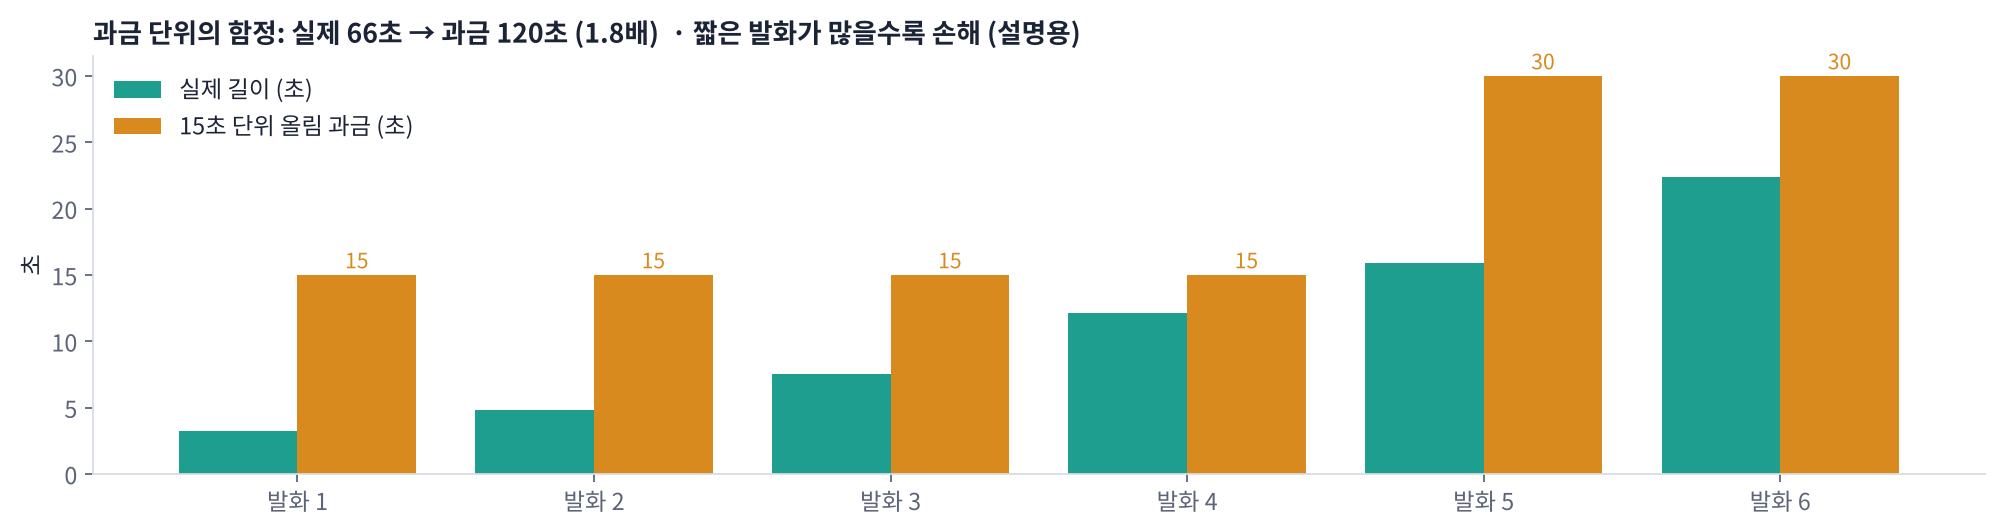

| API | 가격 (USD, 2026-10 확인 기준) | 과금 단위 | 근거 |
|---|---|---|---|
| OpenAI gpt-transcribe | 분당 약 $0.0045 (추정치) | 실제 길이로 계산 (토큰 기반 과금의 추정) | OpenAI 가격 페이지 |
| Google STT v1 | 분당 $0.016 (데이터 로깅 사용) / $0.024 (미사용) | 실제 길이로 계산 (올림 규칙은 요금표 확인) | 요금 안내 (매월 60분 무료) |
| CLOVA CSR | 15초 단위 올림, 단가는 **가정**(15초 5원) | **15초** | CLOVA Speech 장문 예시 · CSR 단가는 콘솔 확인 |

> ⚠️ 가격은 **수업 준비 시점의 참고값**입니다. 실제 결제 전에 각 사 **공식 요금표**를 확인하고 아래 `PRICE`를 고치세요.

> 🎬 **애니메이션 D14-5:** [비용 계산기](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#billing) — 과금 단위 · 발화 길이 · 사용량으로 API와 로컬 GPU의 손익분기 찾기

In [ ]:
# 🧩 빈칸 실습 4
PRICE = {   # usd_per_min: 분당 가격, unit_sec: 과금 단위(초) — None이면 실제 길이 그대로 (올림 규칙은 요금표 확인)
    "OpenAI gpt-transcribe": dict(usd_per_min=0.0045, unit_sec=None),
    "Google STT v1":         dict(usd_per_min=0.016, unit_sec=None),
    "CLOVA CSR":             dict(usd_per_min=5 / CFG["krw_per_usd"] * 4, unit_sec=15),     # 가정: 15초당 5원
}

def billed_seconds(durs, unit):
    return sum(math.____(d / unit) * unit for d in durs)                                     # 빈칸 4

durs = [r["dur"] for r in ROWS]
rows_cost = []
for name, p in PRICE.items():
    b = billed_seconds(durs, p["unit_sec"]) if p["unit_sec"] else sum(durs)
    usd = b / 60 * p["usd_per_min"]
    rows_cost.append(dict(API=name, 실제_분=round(AUDIO_SEC / 60, 1), 과금_분=round(b / 60, 1), 과금배율=round(b / AUDIO_SEC, 2),
                          이번_비용_원=round(usd * CFG["krw_per_usd"], 1), 소리1시간당_USD=round(usd / (AUDIO_SEC / 3600), 3)))
    if name in API_RAW:
        API_RAW[name]["usd_per_hour"] = usd / (AUDIO_SEC / 3600)
display(pd.DataFrame(rows_cost))
check(billed_seconds([3.2, 15.0, 16.0], 15) == 60, hint="빈칸 4 = ceil (올림)")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return sum(math.ceil(d / unit) * unit for d in durs)
```

**해설**: 확인용 예: 3.2초 → 15초, 15.0초 → 15초, 16.0초 → **30초**(15초를 1초만 넘어도 한 단위 더) → 합 60초. 실제 34.2초인데 60초 값을 냅니다. 오늘 시험 세트는 한 문장이 2~10초 정도라 **15초 단위 API는 과금배율이 2배 이상**이 됩니다. 짧은 발화가 많은 서비스(음성 명령, 콜봇)라면 여러 발화를 한 요청으로 묶거나, 초 단위 과금 API를 고르는 것이 유리합니다. 로컬 GPU는 소리 길이가 아니라 **GPU를 켜 둔 시간**으로 과금된다는 점이 다릅니다.

</details>

## Part 5. 리더보드: 한 표로 모으기

> 💬 **쉽게 말하면**: 모든 시스템의 예측을 **같은 normalize()와 CER**로 채점하고, 용어 정확도 · 속도 · 비용 · 외부 전송 여부를 한 표에 놓습니다. **어느 한 열만 보고 고르지 않는 것**이 핵심입니다.

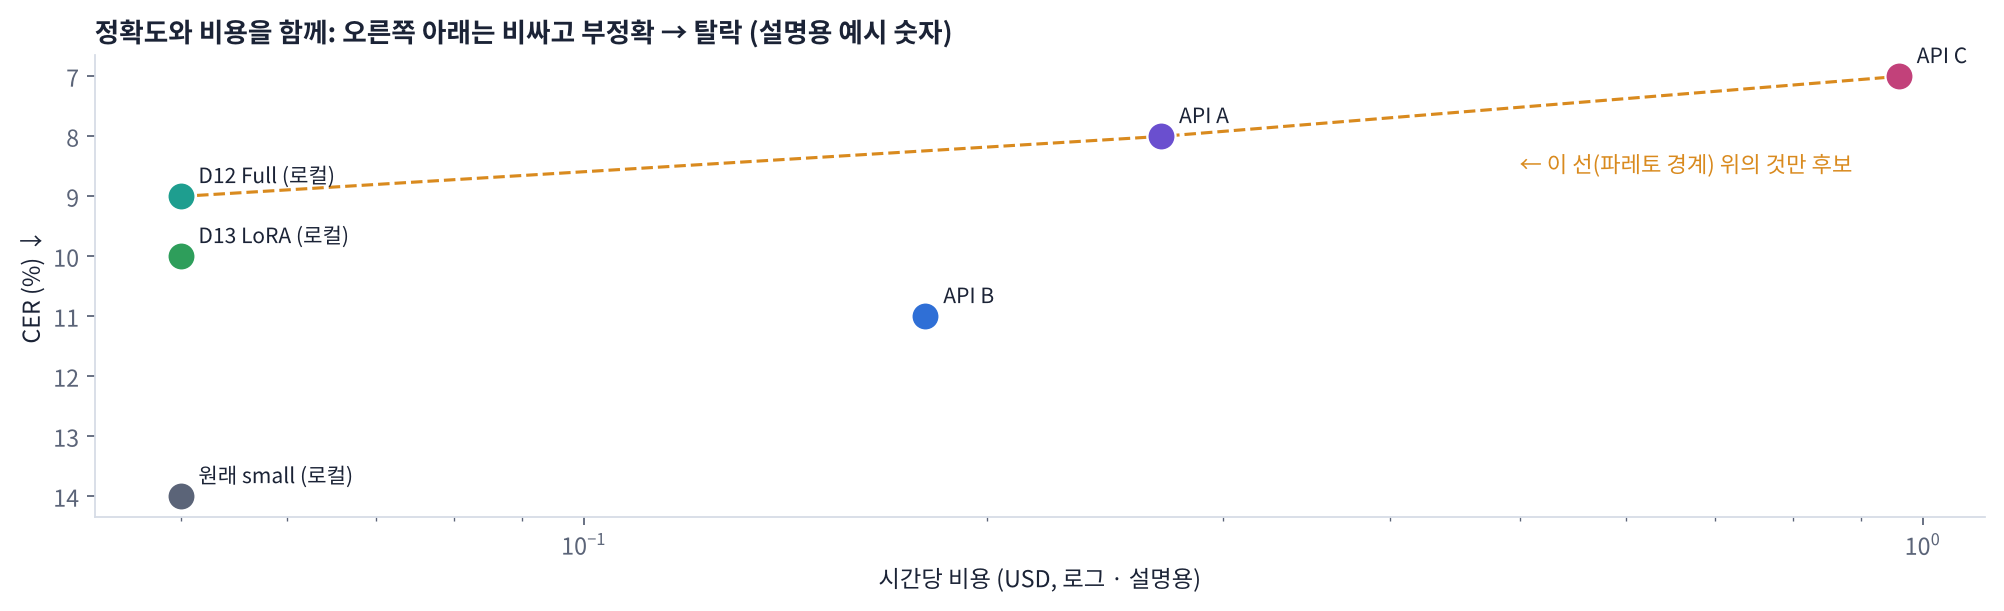

> 🎬 **애니메이션 D14-6:** [나만의 리더보드](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#leaderboard) — 정확도 · 속도 · 비용 · 개인정보의 가중치를 바꾸면 1등이 바뀌는지

In [ ]:
def normalize(s):                                       # D10 · D12 · D13과 같은 채점 기준
    s = re.sub(r"[^\w\s]", "", s.lower())
    return re.sub(r"\s+", "", s)

def cer(rows, preds):
    return 100 * jiwer.cer([normalize(r["text"]) for r in rows], [normalize(p) or "∅" for p in preds])

def term_acc(rows, preds):
    return 100 * float(np.mean([normalize(r["term"]) in normalize(p) for r, p in zip(rows, preds)]))

for name, res in API_RAW.items():
    RESULTS[name] = dict(preds=res["preds"], kind="API", rtf=None, latency=res["latency"],
                         usd_per_hour=res.get("usd_per_hour"), external=True)

gi = [i for i, r in enumerate(ROWS) if r["set"] == "일반"]
di = [i for i, r in enumerate(ROWS) if r["set"] == "도메인"]
pick = lambda seq, idx: [seq[i] for i in idx]
board = []
for name, res in RESULTS.items():
    p = res["preds"]
    board.append({"시스템": name, "종류": res["kind"],
                  "일반 CER(%)": cer(pick(ROWS, gi), pick(p, gi)),
                  "도메인 CER(%)": cer(pick(ROWS, di), pick(p, di)),
                  "용어 정확도(%)": term_acc(pick(ROWS, di), pick(p, di)),
                  "RTF": res["rtf"], "요청당 지연(초)": res["latency"],
                  "소리 1시간당 USD": res["usd_per_hour"], "소리 외부 전송": "예" if res["external"] else "아니요"})
BOARD = pd.DataFrame(board).set_index("시스템")
display(BOARD.round(3).sort_values("일반 CER(%)"))

fig, ax = plt.subplots(figsize=(9, 3.6))
for name, row in BOARD.iterrows():
    ax.scatter(row["소리 1시간당 USD"], row["일반 CER(%)"], s=90)
    ax.annotate(name, (row["소리 1시간당 USD"], row["일반 CER(%)"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.invert_yaxis(); ax.set_xlabel("USD per audio hour (log)"); ax.set_ylabel("general CER (%)  better ↑")
plt.tight_layout(); plt.show()

**결과 읽기** (숫자는 각자 다릅니다)
- **일반 CER**: 보통 ② D12 Full이 ① 원래보다 낮고, 상용 API는 회사 · 모델에 따라 차이가 큽니다.
- **용어 정확도**: ③ D13 LoRA가 자기 도메인에서 강한지, API의 결과는 어떤지 비교합니다. 상용 API 대부분은 **키워드 · 힌트 기능**(OpenAI `keywords[]` · `prompt`, Google `speechContexts` 등)이 있어 학습 없이 용어를 높일 수도 있습니다(과제 2).
- **속도**: 로컬은 묶어서 처리하므로 RTF가 아주 작고, API는 요청마다 네트워크 지연이 붙습니다. 실시간 서비스(5 · 6주차)에서는 '요청당 지연'이 더 중요합니다.
- **비용**: 로컬 비용은 GPU 시간 가정에 크게 좌우됩니다. 소리를 **얼마나 많이** 처리하느냐에 따라 답이 바뀝니다(D14-5 손익분기).

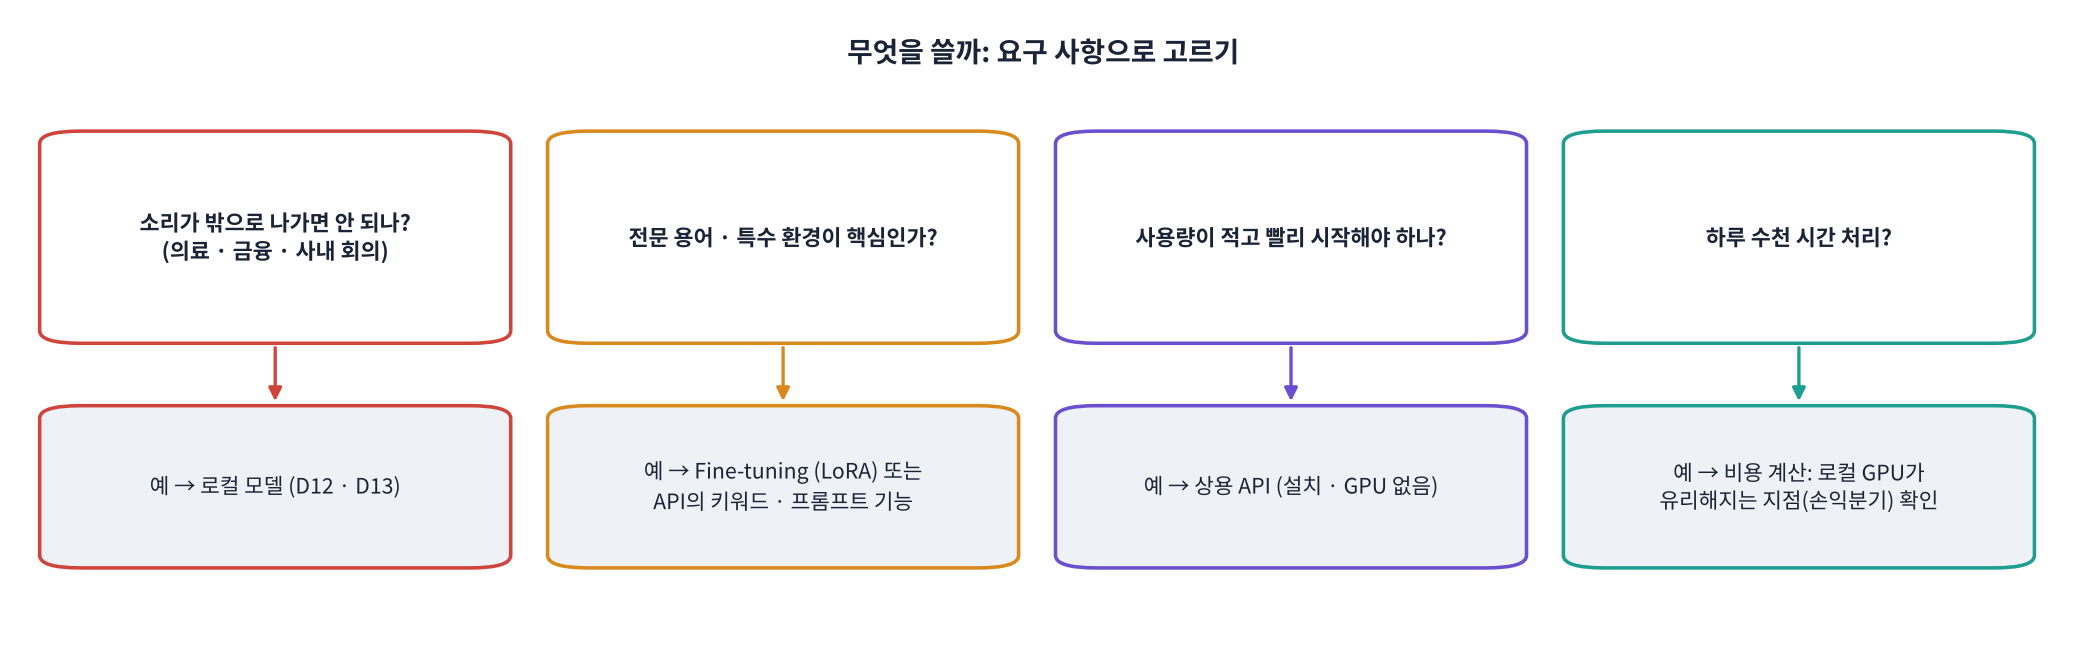

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day14/worksheet.html)** — REST 요청의 다섯 요소, 인증 방식, multipart · base64 · octet-stream, 언어 코드 형식(ko · ko-KR · Kor), 길이 한도, 호출 한도, 과금 단위 올림, 개인정보 · 약관, 모델 종료 일정 확인
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 6. 그 차이, 진짜인가요? 부트스트랩 신뢰구간

> 💬 **쉽게 말하면**: 시험 문장 100개로 잰 CER은 **문장을 어떻게 뽑았느냐에 따라 흔들립니다**. 부트스트랩은 '시험지를 복원 추출로 다시 뽑기'를 수천 번 해서, 두 시스템의 차이가 **얼마나 흔들리는지(신뢰구간)** 를 봅니다. 구간이 **0을 포함하면** '차이가 있다고 말하기 어렵다'입니다.

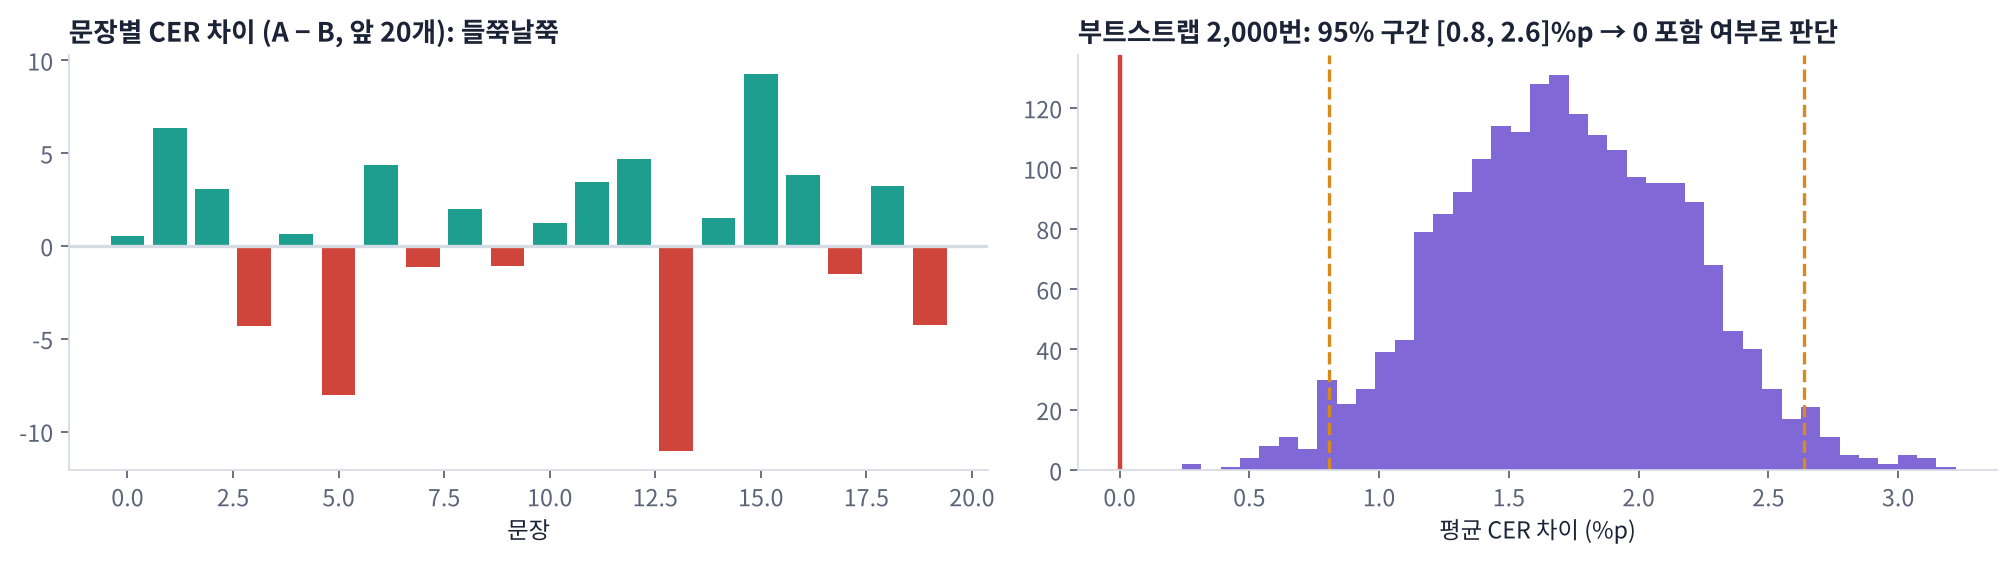

👣 **한 단계씩**
1. 문장마다 두 시스템의 CER을 구한다 (짝을 이룸)
2. 문장 번호를 **같은 개수만큼 복원 추출**(같은 문장이 여러 번 뽑힐 수 있음)
3. 뽑힌 문장들로 평균 CER 차이를 계산 → 2,000번 반복
4. 차이들의 **2.5% ~ 97.5% 지점** = 95% 신뢰구간

> 🎬 **애니메이션 D14-7:** [부트스트랩 실험](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#bootstrap) — 다시 뽑기를 한 번씩 · 1,000번씩 눌러 구간이 생기는 모습

### 🧩 빈칸 실습 5 · 6: 부트스트랩
- 빈칸 5: 한 번 다시 뽑을 때 뽑는 개수 = **원래 문장 수와 같게**
- 빈칸 6: 95% 구간의 위쪽 끝 백분위수

In [ ]:
# 🧩 빈칸 실습 5 · 6
def per_sample_cer(rows, preds):
    return np.array([100 * jiwer.cer(normalize(r["text"]), normalize(p) or "∅") for r, p in zip(rows, preds)])

def bootstrap_diff(a, b, n_boot=2000, seed=0):
    a, b = np.asarray(a), np.asarray(b); n = len(a)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, ____)                                                    # 빈칸 5
        diffs.append(a[idx].mean() - b[idx].mean())
    lo, hi = np.percentile(diffs, [2.5, ____])                                            # 빈칸 6
    return a.mean() - b.mean(), lo, hi, np.array(diffs)

base_name = "① 원래 Whisper"
out = []
for name in RESULTS:
    if name == base_name:
        continue
    for set_name, idx in [("일반", gi), ("도메인", di)]:
        a = per_sample_cer(pick(ROWS, idx), pick(RESULTS[base_name]["preds"], idx))
        b = per_sample_cer(pick(ROWS, idx), pick(RESULTS[name]["preds"], idx))
        d, lo, hi, _ = bootstrap_diff(a, b)
        out.append({"비교": f"원래 − {name}", "세트": set_name, "평균 차이(%p)": d, "95% 하한": lo, "95% 상한": hi,
                    "판정": "개선 ✓" if lo > 0 else ("악화 ✗" if hi < 0 else "차이 불확실")})
display(pd.DataFrame(out).round(2))

_, lo_t, hi_t, diffs_t = bootstrap_diff([5, 3, 8, 0, 2] * 20, [4, 3, 6, 1, 2] * 20)
check(len(diffs_t) == 2000 and lo_t <= np.mean(diffs_t) <= hi_t and hi_t - lo_t < 1.5, hint="빈칸 5 = n, 빈칸 6 = 97.5")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
idx = rng.integers(0, n, n)
lo, hi = np.percentile(diffs, [2.5, 97.5])
```

**해설**: 같은 크기 n으로 **복원 추출**해야 '같은 크기의 다른 시험지'를 흉내 낼 수 있습니다. 차이 = 원래 − 비교 시스템이므로 **양수면 비교 시스템이 더 좋음**(CER이 낮음)입니다. 구간 전체가 0보다 크면 '개선', 0을 포함하면 '이 시험 크기로는 차이를 단정할 수 없음'입니다. 같은 문장끼리 짝을 지어 뽑는 것(paired)이 중요합니다. 문장 난이도가 크게 달라 따로 뽑으면 구간이 쓸데없이 넓어집니다. 참고로 여기서 쓴 '문장별 CER의 평균'은 Part 5의 '전체 글자 기준 CER'과 조금 다를 수 있습니다(긴 문장의 비중 차이).

</details>

## Part 7. 오류 분석: 어디서 왜 틀리나

> 💬 **쉽게 말하면**: CER 한 숫자로는 **무엇을 고쳐야 할지** 모릅니다. 틀린 문장을 종류별로 나눠 세면, '용어 사전을 더하면 될지', '숫자 정규화를 고치면 될지', '데이터를 더 모아야 할지'가 보입니다.

| 종류 | 판정 규칙 (간단판) | 고치는 방법 |
|---|---|---|
| 용어 | 도메인 문장인데 용어가 결과에 없음 | LoRA(D13) · 키워드 힌트 · 후처리 사전 |
| 숫자 표기 | 정답이나 결과에 숫자가 있음 | 정규화(D10) · 데이터 표기 통일 |
| 크게 틀림 | 문장 CER 50% 초과 (누락 · 환각) | 소리 품질 · VAD(D4) · 모델 크기 |
| 일부 글자 | 그 밖의 틀림 | 데이터 추가 · Fine-tuning |

> 🎬 **애니메이션 D14-8:** [오류 종류 탐색기](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#errors) — 시스템별 오류 종류와 실제 문장 보기

In [ ]:
def error_type(r, p):
    c = jiwer.cer(normalize(r["text"]), normalize(p) or "∅")
    if c == 0:
        return None
    if r["term"] and normalize(r["term"]) not in normalize(p):
        return "용어"
    if re.search(r"\d", r["text"] + p):
        return "숫자 표기"
    return "크게 틀림" if c > 0.5 else "일부 글자"

counts = {}
for name, res in RESULTS.items():
    types = [error_type(r, p) for r, p in zip(ROWS, res["preds"])]
    counts[name] = pd.Series([t for t in types if t]).value_counts()
display(pd.DataFrame(counts).fillna(0).astype(int).T)

# 두 시스템의 결과가 가장 많이 다른 문장 보기
names = list(RESULTS)
a_name, b_name = names[0], names[min(1, len(names) - 1)]
diff = sorted(range(len(ROWS)), key=lambda i: -abs(jiwer.cer(normalize(ROWS[i]["text"]), normalize(RESULTS[a_name]["preds"][i]) or "∅")
                                                  - jiwer.cer(normalize(ROWS[i]["text"]), normalize(RESULTS[b_name]["preds"][i]) or "∅")))
for i in diff[:5]:
    print(f"[{ROWS[i]['set']}] 정답: {ROWS[i]['text']}\n  {a_name}: {RESULTS[a_name]['preds'][i]}\n  {b_name}: {RESULTS[b_name]['preds'][i]}\n")

**❓ 생각해 보기**: 상용 API가 일반 CER은 가장 좋은데 우리 도메인 용어는 D13 LoRA보다 못하다면, 무엇을 고를까요?

<details>
<summary>답 보기</summary>

요구 사항에 따라 다릅니다. ① 소리를 외부로 보낼 수 없다면(병원 · 사내 회의) **로컬 D13**이 유일한 선택입니다. ② 보낼 수 있다면 API의 **키워드 · 프롬프트 기능**으로 용어를 먼저 시도해 보고(학습 없이), 그래도 부족하면 로컬 LoRA를 씁니다. ③ 섞어 쓰기도 흔합니다: 평소엔 API, 민감한 녹음은 로컬. 어떤 경우든 **내 실제 녹음**으로 다시 확인합니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day14/worksheet.html)** — 리더보드 열 읽기, 파레토 경계, 손익분기, 부트스트랩(복원 추출 · n · 2.5/97.5 · paired), 신뢰구간 판정, 오류 종류와 해결책
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 8. Hugging Face Hub에 올리기

> 💬 **쉽게 말하면**: Hub는 **모델의 GitHub**입니다. 저장소를 만들고 폴더를 올리면, 어디서든 `from_pretrained("사용자명/모델이름")` 한 줄로 받아 씁니다. 함께 올리는 **모델 카드(README.md)** 에는 기반 모델 · 데이터 · 성능 · 한계 · 라이선스를 적습니다.

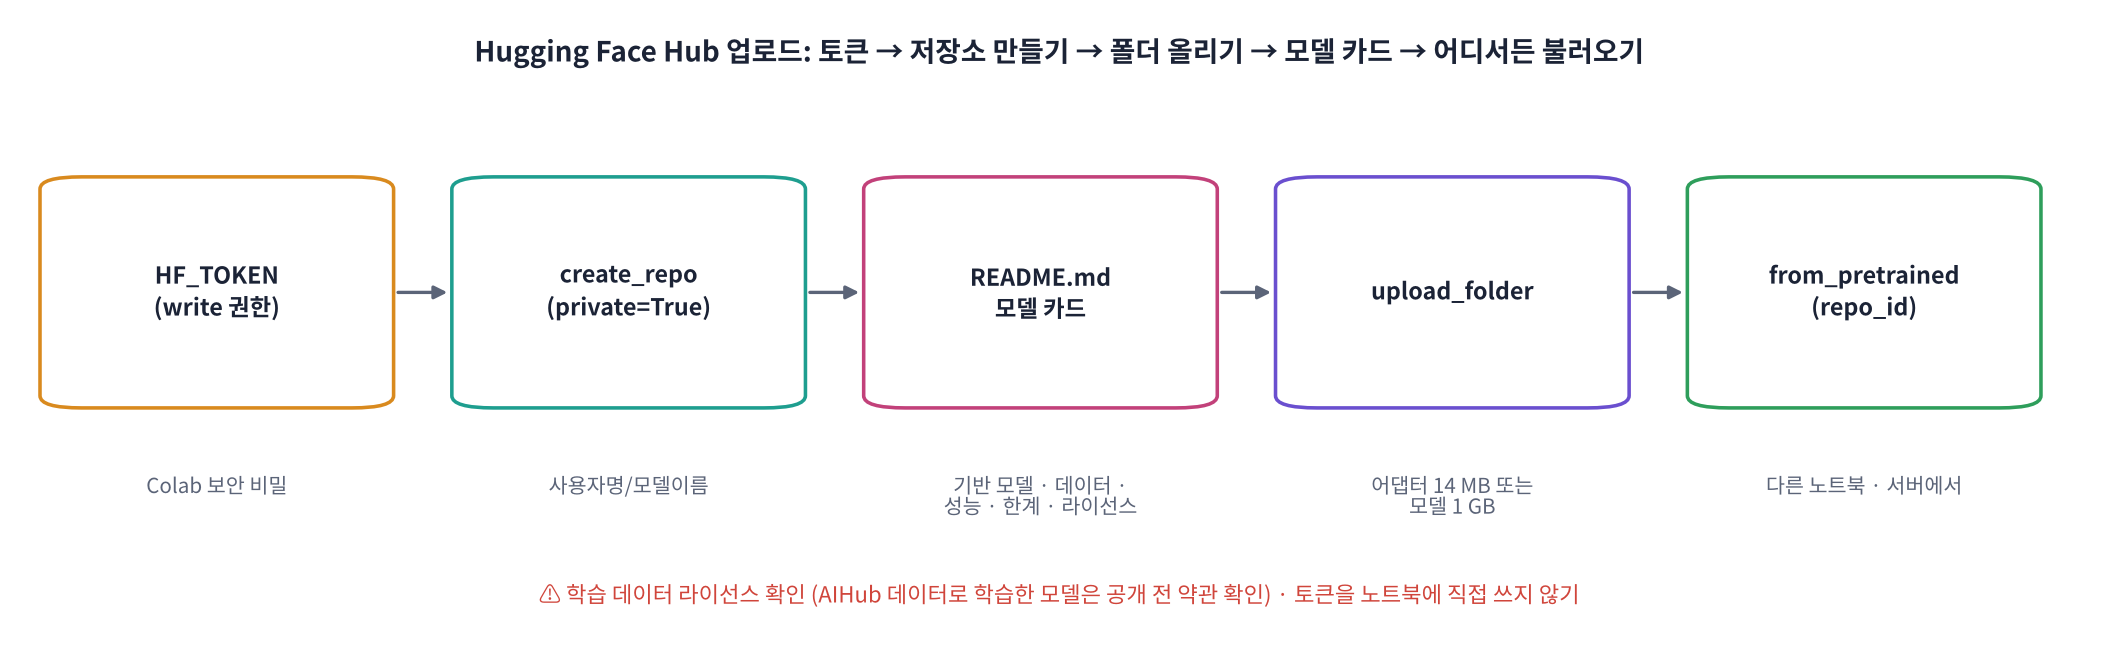

👣 **준비**: [huggingface.co](https://huggingface.co) 가입 → Settings → Access Tokens → **write** 권한 토큰 → Colab 🔑 보안 비밀에 `HF_TOKEN`으로 저장.

| 올릴 것 | 크기 | 쓰는 쪽 코드 |
|---|---|---|
| D13 LoRA 어댑터 (있으면 우선) | 약 14 MB | `PeftModel.from_pretrained(원래 모델, repo_id)` |
| D12 Full 모델 | 약 1 GB | `WhisperForConditionalGeneration.from_pretrained(repo_id)` |

> ⚠️ **공개 전 확인**: ① 학습 데이터 라이선스(Zeroth는 CC BY 4.0 → 출처 표시, **AIHub 데이터로 학습한 모델은 약관상 공개가 제한될 수 있음**) ② 오늘은 **비공개(private)** 로 올립니다 ③ 토큰을 코드 · 모델 카드에 절대 쓰지 않기.

> 🎬 **애니메이션 D14-9:** [모델 카드 만들기](https://imguru-mooc.github.io/AI_Voice/day14/animation.html#hub) — 항목을 채우면 README.md 미리보기가 만들어짐

### 8-1. 모델 카드 쓰기
위쪽 `---` 사이는 **메타데이터**(YAML)로 Hub가 읽어 검색 · 위젯에 씁니다. 아래는 사람이 읽는 설명입니다. 오늘 리더보드 숫자를 그대로 넣습니다.

In [ ]:
IS_LORA = D13_DIR is not None
UPLOAD_SRC = D13_DIR or D12_DIR
my_name = "③ D13 LoRA" if IS_LORA else "② D12 Full"

def board_row(name):
    if name not in BOARD.index:
        return "| (이번 실행에 없음) | | | |"
    r = BOARD.loc[name]
    return f"| {name} | {r['일반 CER(%)']:.2f} | {r['도메인 CER(%)']:.2f} | {r['용어 정확도(%)']:.1f} |"

usage = (f'from transformers import WhisperForConditionalGeneration\nfrom peft import PeftModel\n'
         f'base = WhisperForConditionalGeneration.from_pretrained("{CFG["model_name"]}")\nmodel = PeftModel.from_pretrained(base, "REPO_ID")'
         if IS_LORA else
         'from transformers import pipeline\nasr = pipeline("automatic-speech-recognition", model="REPO_ID")')
CARD = f'''---
language: ko
license: apache-2.0
base_model: {CFG["model_name"]}
library_name: {"peft" if IS_LORA else "transformers"}
pipeline_tag: automatic-speech-recognition
tags: [whisper, korean{", lora, " + EN if IS_LORA else ""}]
datasets: [kresnik/zeroth_korean]
metrics: [cer]
---
# {CFG["model_name"].split("/")[-1]} 한국어 {"LoRA (" + CFG["domain"] + " 용어)" if IS_LORA else "Full Fine-tuning"}

음성 AI 전문가 과정 실습 모델입니다 (D12 Full Fine-tuning / D13 LoRA).

## 성능 (D14 시험 세트 · 문장 부호와 띄어쓰기를 지운 뒤 CER)
| 시스템 | 일반 CER(%) | 도메인 CER(%) | 용어 정확도(%) |
|---|---|---|---|
{board_row("① 원래 Whisper")}
{board_row(my_name)}

- 일반: Zeroth-Korean 공식 test에서 무작위 {len(gi)}문장
- 도메인: {CFG["domain"]} 용어 {len(TERMS)}개 × 처음 보는 문장 틀 {len(TEST_TEMPLATES)}개, gTTS 합성음

## 학습 데이터
- Zeroth-Korean (CC BY 4.0){", 도메인 용어 문장(gTTS 합성) + Zeroth 일반 문장 replay" if IS_LORA else ""}

## 한계
- 도메인 시험은 합성음(한 목소리)이라 실제 사람 목소리보다 점수가 좋게 나올 수 있습니다.
- 학습에 없던 용어 · 말투 · 녹음 환경에서는 성능이 떨어질 수 있습니다.

## 사용법
```python
{usage}
```
'''
print(CARD[:900])

### 🧩 빈칸 실습 7 · 8 · 9: 저장소 만들기 → 올리기 → 다시 불러오기
- 빈칸 7: 오늘은 **비공개**로 만듭니다 (`private=`에 넣을 값)
- 빈칸 8: 폴더 통째로 올리는 `HfApi` 메서드 이름
- 빈칸 9: 다시 불러올 때 쓰는 **저장소 이름 변수** (두 곳)

In [ ]:
# 🧩 빈칸 실습 7 · 8 · 9
from huggingface_hub import HfApi

repo_id, back = None, None
if KEYS["HF_TOKEN"] and UPLOAD_SRC:
    api = HfApi(token=KEYS["HF_TOKEN"])
    user = api.whoami()["name"]
    repo_id = f"{user}/{CFG['model_name'].split('/')[-1]}-ko-{EN + '-lora' if IS_LORA else 'd12'}"
    api.create_repo(repo_id, private=____, exist_ok=True)                                 # 빈칸 7

    shutil.rmtree("hub_upload", ignore_errors=True)
    shutil.copytree(UPLOAD_SRC, "hub_upload", ignore=shutil.ignore_patterns("checkpoint-*", "runs", "*.pt"))
    open("hub_upload/README.md", "w", encoding="utf-8").write(CARD.replace("REPO_ID", repo_id))
    processor.save_pretrained("hub_upload")
    t0 = time.time()
    api.____(folder_path="hub_upload", repo_id=repo_id)                                      # 빈칸 8
    print(f"업로드 완료: https://huggingface.co/{repo_id}  ({time.time() - t0:.0f}초)")
    print("올라간 파일:", api.list_repo_files(repo_id))

    if IS_LORA:                                                                               # 빈칸 9 (두 곳)
        back = PeftModel.from_pretrained(WhisperForConditionalGeneration.from_pretrained(CFG["model_name"]), ____)
    else:
        back = WhisperForConditionalGeneration.from_pretrained(____)
    back = prep(back.merge_and_unload() if IS_LORA else back)
    r = domain[0] if IS_LORA else general[0]
    print("다시 불러와 받아쓰기:", transcribe_local(back, [r])[0], "| 정답:", r["text"])
    check(back is not None and repo_id is not None and "README.md" in api.list_repo_files(repo_id),
          hint="빈칸 7 = True, 빈칸 8 = upload_folder, 빈칸 9 = repo_id")
else:
    print("HF_TOKEN 또는 올릴 폴더(D12 · D13)가 없어 건너뜁니다 → 🔑 정답을 펼쳐 코드를 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
api.create_repo(repo_id, private=True, exist_ok=True)
api.upload_folder(folder_path="hub_upload", repo_id=repo_id)
back = PeftModel.from_pretrained(WhisperForConditionalGeneration.from_pretrained(CFG["model_name"]), repo_id)
back = WhisperForConditionalGeneration.from_pretrained(repo_id)
```

**해설**: `private=True`면 나만(또는 조직 구성원만) 볼 수 있고, 나중에 웹의 Settings에서 공개로 바꿀 수 있습니다. `exist_ok=True`는 이미 있으면 그대로 쓰라는 뜻입니다(다시 실행해도 오류 없음). `upload_folder`는 폴더 안 파일을 한 번의 커밋으로 올립니다(큰 파일은 자동으로 나눠 올림). 다시 불러올 때 로컬 폴더 경로 대신 **저장소 이름**을 주면 Hub에서 내려받습니다. 비공개 저장소는 같은 토큰으로 로그인한 상태에서만 받을 수 있습니다. 웹 페이지에서 모델 카드가 표로 잘 보이는지도 확인하세요.

</details>

---
### 📝 4교시 마무리: 개념 워크시트 · 제출

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day14/worksheet.html)** — Hub 저장소 · 토큰 권한, create_repo · upload_folder, private, 모델 카드 메타데이터와 본문, 데이터 라이선스, 어댑터 vs 전체 모델 공유, 다시 불러오기, 시스템 선택 기준
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 9. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| 공정한 비교 | 같은 시험지 · 같은 채점 · 누수 없음 · 정확도 외 지표 · 신뢰구간 | `normalize()` + `jiwer.cer` |
| RTF | 처리 시간 ÷ 소리 길이 | `elapsed / AUDIO_SEC` |
| REST API | URL · 인증 · 소리 · 옵션 → JSON | `requests.post(url, headers=…, data/json/files=…)` |
| 언어 코드 | OpenAI `ko` · Google `ko-KR` · CLOVA `Kor` | `languages[]`, `languageCode`, `lang` |
| 과금 | 요청마다 단위 시간 올림 × 분당 가격 | `math.ceil(d / unit) * unit` |
| 리더보드 | CER · 용어 · 속도 · 비용 · 외부 전송 | `BOARD` |
| 부트스트랩 | 같은 크기 복원 추출 → 2.5 ~ 97.5% | `rng.integers(0, n, n)` |
| 오류 분석 | 종류별로 세어 고칠 곳 찾기 | `error_type()` |
| Hub | 저장소 → 폴더 업로드 → 모델 카드 → 불러오기 | `create_repo`, `upload_folder`, `from_pretrained(repo_id)` |

### 📝 과제 (D15 미니 프로젝트 준비)
1. **내 목소리 시험 세트**: 일상 문장 10개 + 도메인 문장 10개를 직접 녹음해 오늘의 모든 시스템으로 다시 채점하세요. 순위가 바뀌었나요?
2. **API 키워드 기능**: OpenAI `keywords[]`(또는 `prompt`)에 도메인 용어 목록을 넣어 용어 정확도가 얼마나 오르는지, D13 LoRA와 비교하세요.
3. **손익분기**: 하루 처리량을 1 · 10 · 100 · 1,000시간으로 바꿔 가며 'API 하나 vs 로컬 GPU 상시 운영' 월 비용을 표로 만들고, 몇 시간부터 로컬이 유리한지 찾으세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D14 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day14/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. **리더보드 표 · 부트스트랩 표 · Hub 저장소 주소**도 함께 붙이세요.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day14/animation.html) — D14-1 ~ D14-9

### 다음 시간 (D15 · 3주차 미니 프로젝트)
**도메인 특화 한국어 ASR 모델 구축 + 성능 리포트**: 팀별로 도메인을 정해 데이터 만들기(D11) → LoRA 학습(D13) → 오늘의 비교 · 부트스트랩 · 오류 분석(D14) → Hub 업로드와 모델 카드까지 하루에 완성하고 발표합니다. 오늘 노트북이 리포트의 뼈대가 됩니다.